# 📊 Ciclos Macro
Notebook 01: Preprocessing

## Preliminares

In [1]:
import pandas as pd
from src.extract import fetch_fred, fetch_prices
from src.preprocessing_functions import *
from src.config import clean_data_file, daily_cols, monthly_cols

### Extraer datos macro

In [2]:
df_macro = fetch_fred()
df_macro.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5501 entries, 2006-01-01 to 2026-10-22
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   real_yield_10y             5206 non-null   float64
 1   dxy_broad_goods            5212 non-null   float64
 2   vix_index                  5267 non-null   float64
 3   st_louis_financial_stress  1085 non-null   float64
 4   industrial_production      249 non-null    float64
 5   unemployment_rate          248 non-null    float64
 6   cpi_headline               248 non-null    float64
 7   fed_funds_rate             249 non-null    float64
 8   m2_money_supply            248 non-null    float64
dtypes: float64(9)
memory usage: 429.8 KB


In [3]:
# Se remuestran a fin de mes aplicando lag de 1 periodo a series macro mensuales
df_macro_monthly = process_macro_to_monthly(df_raw=df_macro, daily_columns=daily_cols, monthly_columns=monthly_cols)
df_macro_monthly.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 249 entries, 2006-01-31 to 2026-09-30
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   real_yield_10y              249 non-null    float64
 1   dxy_broad_goods             249 non-null    float64
 2   vix_index                   249 non-null    float64
 3   st_louis_financial_stress   249 non-null    float64
 4   industrial_production_lag1  248 non-null    float64
 5   unemployment_rate_lag1      247 non-null    float64
 6   cpi_headline_lag1           247 non-null    float64
 7   fed_funds_rate_lag1         248 non-null    float64
 8   m2_money_supply_lag1        248 non-null    float64
dtypes: float64(9)
memory usage: 19.5 KB


In [4]:
df_macro_monthly.head()

,real_yield_10y,dxy_broad_goods,vix_index,st_louis_financial_stress,industrial_production_lag1,unemployment_rate_lag1,cpi_headline_lag1,fed_funds_rate_lag1,m2_money_supply_lag1
date,,,,,,,,,
2006-01-31,2.00,99.4311,12.95,-0.9948,NaN,NaN,NaN,NaN,NaN
2006-02-28,2.02,99.7695,12.34,-1.1061,98.1999,4.7,199.3,4.29,6728.4
2006-03-31,2.35,100.5600,11.39,-1.0447,98.2413,4.8,199.4,4.49,6753.1
2006-04-30,2.39,98.1412,11.59,-1.0928,98.4628,4.7,199.7,4.59,6766.9
2006-05-31,2.48,97.7705,16.44,-0.7809,98.7618,4.7,200.7,4.79,6806.3


In [5]:
# Mostrar missings
show_missings(df_macro_monthly)

unemployment_rate_lag1        0.008032
cpi_headline_lag1             0.008032
industrial_production_lag1    0.004016
fed_funds_rate_lag1           0.004016
m2_money_supply_lag1          0.004016
dtype: float64

In [6]:
# Ver datos faltantes
print(df_macro_monthly[df_macro_monthly["cpi_headline_lag1"].isna()])

            real_yield_10y  dxy_broad_goods  vix_index  \
date                                                     
2006-01-31            2.00          99.4311      12.95   
2025-11-30            1.79         121.0527      16.35   

            st_louis_financial_stress  industrial_production_lag1  \
date                                                                
2006-01-31                    -0.9948                         NaN   
2025-11-30                    -0.3798                    101.2195   

            unemployment_rate_lag1  cpi_headline_lag1  fed_funds_rate_lag1  \
date                                                                         
2006-01-31                     NaN                NaN                  NaN   
2025-11-30                     NaN                NaN                 4.09   

            m2_money_supply_lag1  
date                              
2006-01-31                   NaN  
2025-11-30               22249.8  


In [7]:
# Se aplica forward fill y se mantienen missings iniciales
df_macro_monthly = df_macro_monthly.ffill(limit=1)
show_missings(df_macro_monthly)

industrial_production_lag1    0.004016
unemployment_rate_lag1        0.004016
cpi_headline_lag1             0.004016
fed_funds_rate_lag1           0.004016
m2_money_supply_lag1          0.004016
dtype: float64

### Extraer precios

In [8]:
df_prices = fetch_prices()

# Se elimina la fila del mes en curso
df_historical_prices = drop_incomplete_month(df_prices)

df_historical_prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 249 entries, 2006-01-31 to 2026-09-30
Freq: ME
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   oil     249 non-null    float64
 1   gold    249 non-null    float64
 2   spy     249 non-null    float64
dtypes: float64(3)
memory usage: 7.8 KB


### Unir datasets

In [9]:
df_merged = df_macro_monthly.join(df_historical_prices, how="inner")
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 249 entries, 2006-01-31 to 2026-09-30
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   real_yield_10y              249 non-null    float64
 1   dxy_broad_goods             249 non-null    float64
 2   vix_index                   249 non-null    float64
 3   st_louis_financial_stress   249 non-null    float64
 4   industrial_production_lag1  248 non-null    float64
 5   unemployment_rate_lag1      248 non-null    float64
 6   cpi_headline_lag1           248 non-null    float64
 7   fed_funds_rate_lag1         248 non-null    float64
 8   m2_money_supply_lag1        248 non-null    float64
 9   oil                         249 non-null    float64
 10  gold                        249 non-null    float64
 11  spy                         249 non-null    float64
dtypes: float64(12)
memory usage: 25.3 KB


## Feature Engineering

In [10]:
# Variaciones porcentuales mensuales
monthly_return_cols = [
    'oil',
    'gold',
    'spy',
    'dxy_broad_goods',
    'vix_index',
]
df_features = calculate_return(df_merged, cols=monthly_return_cols, periods=1)

# Variaciones porcentuales YoY
yearly_return_cols = [
    'oil',
    'gold',
    'spy',
    'cpi_headline_lag1',
    'industrial_production_lag1',
    'm2_money_supply_lag1'
]
df_features = calculate_return(df_features, cols=yearly_return_cols, periods=12)

# Cambios absolutos en variables originales porcentuales mensuales
monthly_yield_cols = [
    'real_yield_10y',
    'st_louis_financial_stress'
]
df_features = calculate_delta(df_features, cols=monthly_yield_cols, periods=1)

# Cambios absolutos YoY
yearly_yield_cols = [
    'unemployment_rate_lag1',
    'fed_funds_rate_lag1'
]
df_features = calculate_delta(df_features, cols=yearly_yield_cols, periods=12)

# Cambios absolutos QoQ: se aplica sobre las mismas columnas que el anual
df_features = calculate_delta(df_features, cols=yearly_yield_cols, periods=3)

# Se eliminan columnas base originales no estacionarias
base_cols_to_drop = [
    'oil',
    'gold', 
    #'spy', # Se mantiene para visualizar en la fase de modelado
    'dxy_broad_goods',
    'cpi_headline_lag1',
    'industrial_production_lag1',
    'unemployment_rate_lag1',
    'm2_money_supply_lag1',
    'fed_funds_rate_lag1'
]
df_features = df_features.drop(columns=base_cols_to_drop)

df_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 249 entries, 2006-01-31 to 2026-09-30
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   real_yield_10y                       249 non-null    float64
 1   vix_index                            249 non-null    float64
 2   st_louis_financial_stress            249 non-null    float64
 3   spy                                  249 non-null    float64
 4   oil_ret_1m                           248 non-null    float64
 5   gold_ret_1m                          248 non-null    float64
 6   spy_ret_1m                           248 non-null    float64
 7   dxy_broad_goods_ret_1m               248 non-null    float64
 8   vix_index_ret_1m                     248 non-null    float64
 9   oil_ret_12m                          237 non-null    float64
 10  gold_ret_12m                         237 non-null    float64
 11  spy_ret_12m  

In [11]:
# Se eliminan missings iniciales luego del calculo de las diferencias
df_features = df_features.dropna()

## EDA

In [12]:
df_features.describe()

,real_yield_10y,vix_index,st_louis_financial_stress,spy,oil_ret_1m,gold_ret_1m,spy_ret_1m,dxy_broad_goods_ret_1m,vix_index_ret_1m,oil_ret_12m,...,spy_ret_12m,cpi_headline_lag1_ret_12m,industrial_production_lag1_ret_12m,m2_money_supply_lag1_ret_12m,real_yield_10y_change_1m,st_louis_financial_stress_change_1m,unemployment_rate_lag1_change_12m,fed_funds_rate_lag1_change_12m,unemployment_rate_lag1_change_3m,fed_funds_rate_lag1_change_3m
count,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,...,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000,236.000000
mean,0.784195,19.873178,0.055813,285.806567,0.008696,0.009163,0.008101,0.001049,0.029153,0.075693,...,0.102201,0.025427,0.002667,0.063705,0.002246,0.001352,-0.015254,-0.061780,-0.003814,-0.020551
std,0.992888,8.067458,1.179975,173.100564,0.119019,0.050122,0.044676,0.017692,0.251537,0.404174,...,0.159209,0.019282,0.046312,0.052028,0.227167,0.627821,1.964477,1.401708,1.242897,0.444621
min,-1.160000,9.510000,-1.121600,73.930000,-0.542449,-0.180050,-0.165187,-0.048312,-0.458969,-0.705210,...,-0.447542,-0.019588,-0.173183,-0.046407,-0.630000,-2.955300,-8.700000,-4.100000,-4.800000,-1.660000
25%,0.150000,14.500000,-0.582625,142.112495,-0.056253,-0.020260,-0.016892,-0.010470,-0.138624,-0.170452,...,0.027332,0.014924,-0.012921,0.040071,-0.122500,-0.211750,-0.800000,-0.690000,-0.200000,-0.022500
50%,0.660000,17.455000,-0.242400,221.955002,0.013771,0.006853,0.013878,-0.001082,-0.015779,0.021860,...,0.130282,0.022351,0.012052,0.059724,-0.020000,-0.018000,-0.300000,0.010000,-0.100000,0.000000
75%,1.672500,23.385000,0.185625,406.780006,0.064332,0.041680,0.034034,0.013372,0.131685,0.241550,...,0.190661,0.032460,0.027725,0.072356,0.130000,0.198400,0.300000,0.302500,0.100000,0.030000
max,3.140000,59.890000,7.804900,767.049988,0.883758,0.138672,0.126984,0.079986,1.345710,2.374735,...,0.537653,0.089794,0.165521,0.267776,1.010000,4.701800,11.100000,4.500000,11.200000,1.560000


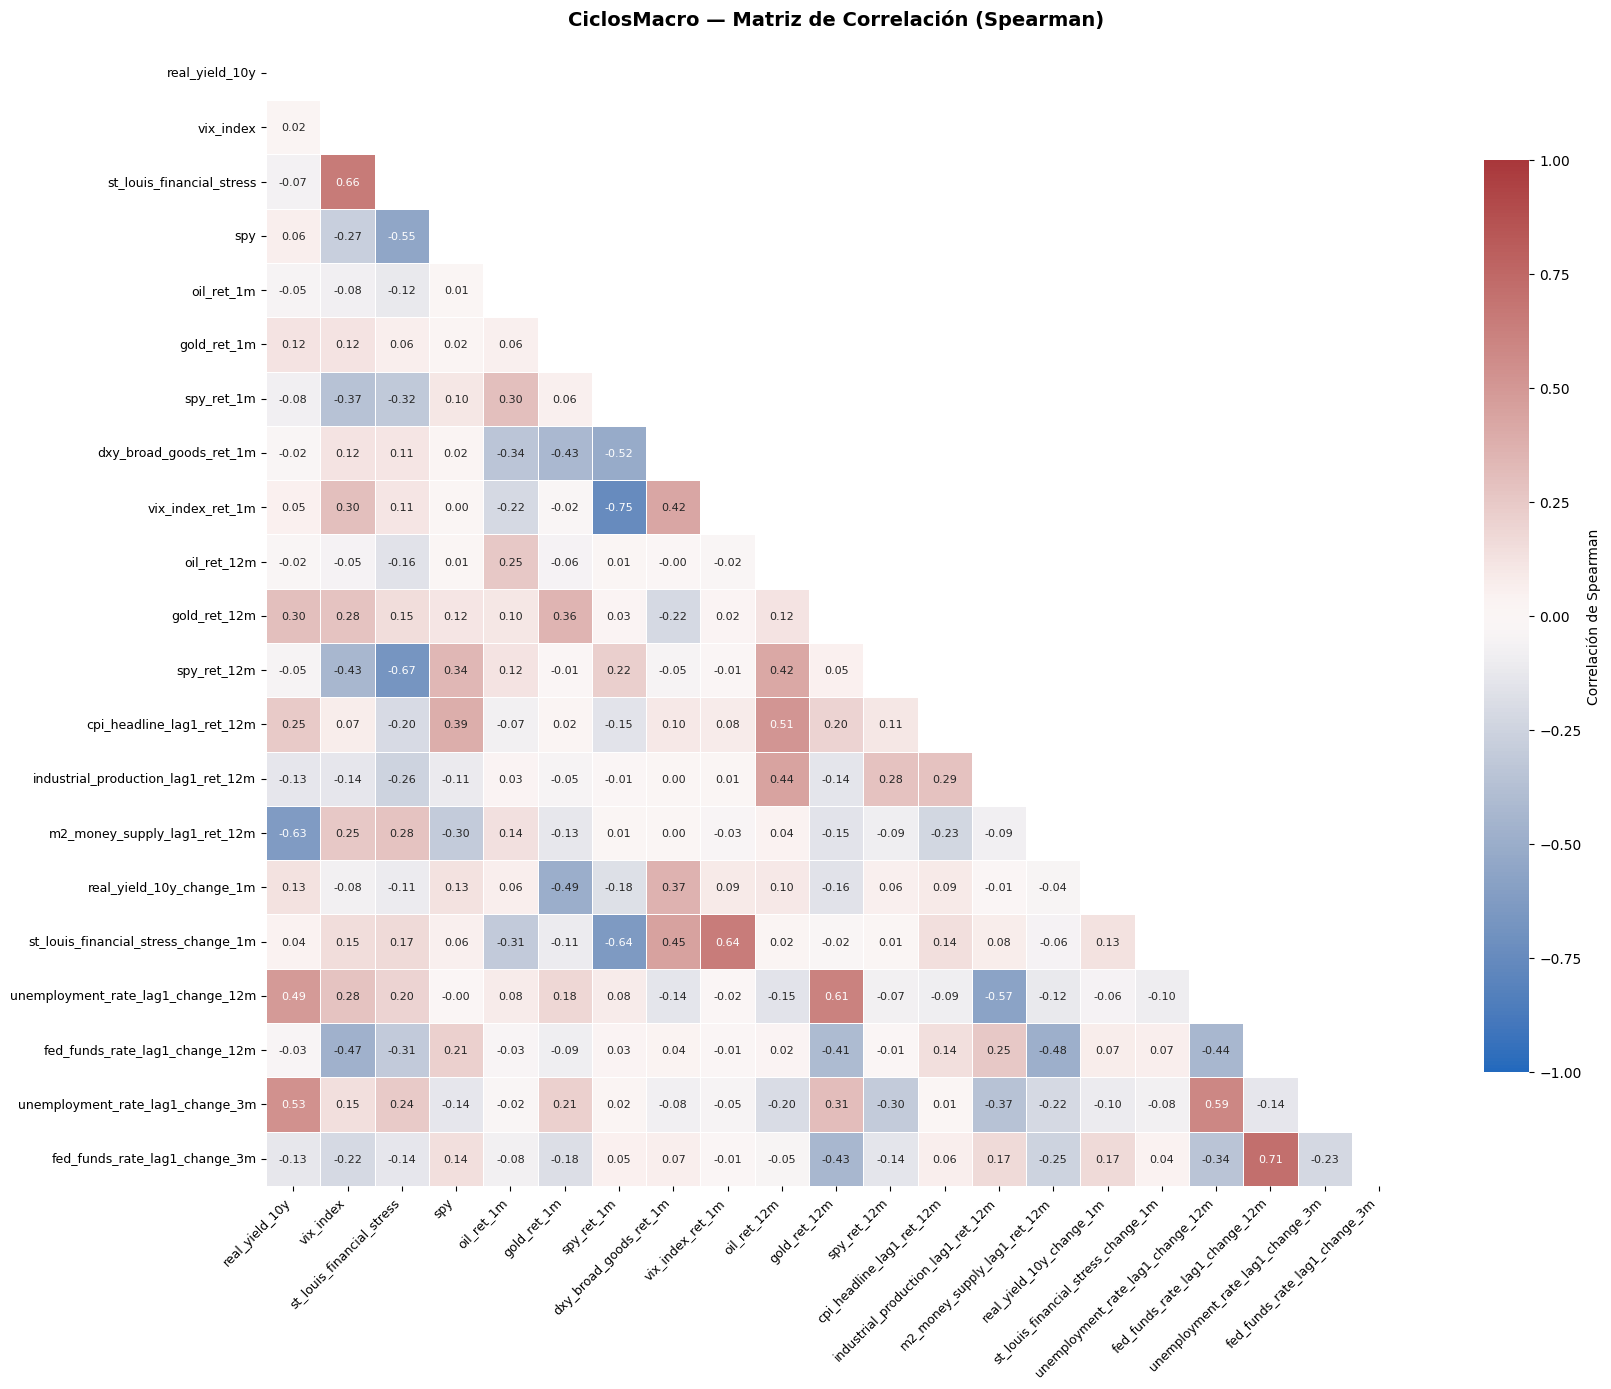


--- Pares con mayor redundancia / correlación extrema ---
                              feature_1                           feature_2  correlation
0                      vix_index_ret_1m                          spy_ret_1m    -0.747743
1         fed_funds_rate_lag1_change_3m      fed_funds_rate_lag1_change_12m     0.713357
2                           spy_ret_12m           st_louis_financial_stress    -0.673003
3             st_louis_financial_stress                           vix_index     0.656014
4   st_louis_financial_stress_change_1m                    vix_index_ret_1m     0.644323
5   st_louis_financial_stress_change_1m                          spy_ret_1m    -0.638608
6          m2_money_supply_lag1_ret_12m                      real_yield_10y    -0.628594
7     unemployment_rate_lag1_change_12m                        gold_ret_12m     0.611764
8      unemployment_rate_lag1_change_3m   unemployment_rate_lag1_change_12m     0.586072
9     unemployment_rate_lag1_change_12m  industrial

In [13]:
# Matriz de correlaciones
corr_matrix, top_redundant_pairs = plot_correlation_matrix(
    df=df_features,
    method="spearman",
    figsize=(18, 14),
    top_n_pairs=12,
)

print("\n--- Pares con mayor redundancia / correlación extrema ---")
print(top_redundant_pairs.to_string())

* `m2_money_supply_lag1_ret_12m` vs `real_yield_10y`: Refleja la postura monetaria de la Reserva Federal. Una expansión monetaria acelerada deprime las tasas reales, mientras que una contracción de liquidez dispara los rendimientos de los bonos.
* `vix_index_ret_1m` vs  `spy_ret_1m` / `st_louis_financial_stress_change_1m` vs `spy_ret_1m` / `spy_ret_12m` vs `st_louis_financial_stress` / `st_louis_financial_stress_change_1m` vs `vix_index_ret_1m` - Bloque de Aversión al Riesgo y Estrés. El mercado de renta variable reacciona de forma simétrica a la volatilidad implícita y a la tensión en los mercados de crédito.
* `fed_funds_rate_lag1_change_3m` vs `fed_funds_rate_lag1_change_12m`: Colinealidad inducida por construcción temporal. Si la Fed esta subiendo tasas en 12 meses, la variación de los últimos 3 meses también sera positiva.
* `unemployment_rate_lag1_change_12m` vs `gold_ret_12m`: Cobertura macro. El aumento sostenido del desempleo indica riesgo recesivo o estanflacionario, impulsando la demanda de oro como refugio.
* `unemployment_rate_lag1_change_12m` vs `industrial_production_lag1_ret_12m`: Ley de Okun empírica. Cuando la producción industrial colapsa año contra año, el desempleo se acelera en la misma proporción.
* `st_louis_financial_stress` vs `vix_index`:  Que el VIX y el índice de Saint Louis solo tengan un 51% de correlación señala que aportan información complementaria.
* `cpi_headline_lag1_ret_12m` vs `oil_ret_12m`: El petróleo como vector principal del componente energético en el IPC general.

Luego de analizar los 3 pares con mayor correlación, se determina:
* **Par 0**: A pesar de exhibir una correlación lineal pronunciada ($-0.88$), se decide conservar tanto `m2_money_supply_lag1_ret_12m` como `real_yield_10y`, porque ambas métricas capturan dimensiones económicas ortogonales de la postura monetaria: mientras la masa monetaria M2 mide la oferta agregada de liquidez en el sistema, la tasa real a 10 años refleja el costo efectivo del capital y las expectativas de crecimiento ajustadas por inflación, permitiendo a PCA comprimir esta relación macroeconómica sin pérdida de señal sustancial. 
* **Par 1**: De forma similar, se mantiene el Par 1 (`vix_index_ret_1m` vs. `spy_ret_1m`, con $-0.76$) dado que representan la rentabilidad mensual de la renta variable y la volatilidad implícita esperada, constituyendo el núcleo del factor de apetito por riesgo (Risk-On / Risk-Off). 
* **Par 2**: (`fed_funds_rate_lag1_change_3m` vs. `fed_funds_rate_lag1_change_12m`, con $+0.72$), la asociación se origina por una redundancia temporal artificial al medir la misma tasa bajo dos ventanas superpuestas; por ello, se elimina la variación de corto plazo (3 meses) para evitar un sobrepeso artificial de la política monetaria sobre los primeros autovectores de PCA, preservando la métrica de 12 meses como el indicador estructural del ciclo de ajuste o flexibilización de la Reserva Federal.

In [14]:
# Se elimina la columna redundante
df_features.drop('fed_funds_rate_lag1_change_3m', axis=1, inplace=True)

In [15]:
# Ver asimetrías
show_asymmetry(df_features)

unemployment_rate_lag1_change_3m       5.218327
st_louis_financial_stress              3.556678
st_louis_financial_stress_change_1m    2.066286
vix_index                              2.017265
m2_money_supply_lag1_ret_12m           1.548743
oil_ret_12m                            1.480572
oil_ret_1m                             1.464026
vix_index_ret_1m                       1.431929
unemployment_rate_lag1_change_12m      1.310931
cpi_headline_lag1_ret_12m              1.109424
spy                                    1.026533
real_yield_10y_change_1m               0.674835
dxy_broad_goods_ret_1m                 0.559001
gold_ret_12m                           0.537232
fed_funds_rate_lag1_change_12m         0.342697
real_yield_10y                        -0.023345
gold_ret_1m                           -0.191766
spy_ret_1m                            -0.535778
spy_ret_12m                           -0.872715
industrial_production_lag1_ret_12m    -1.219337


Cont


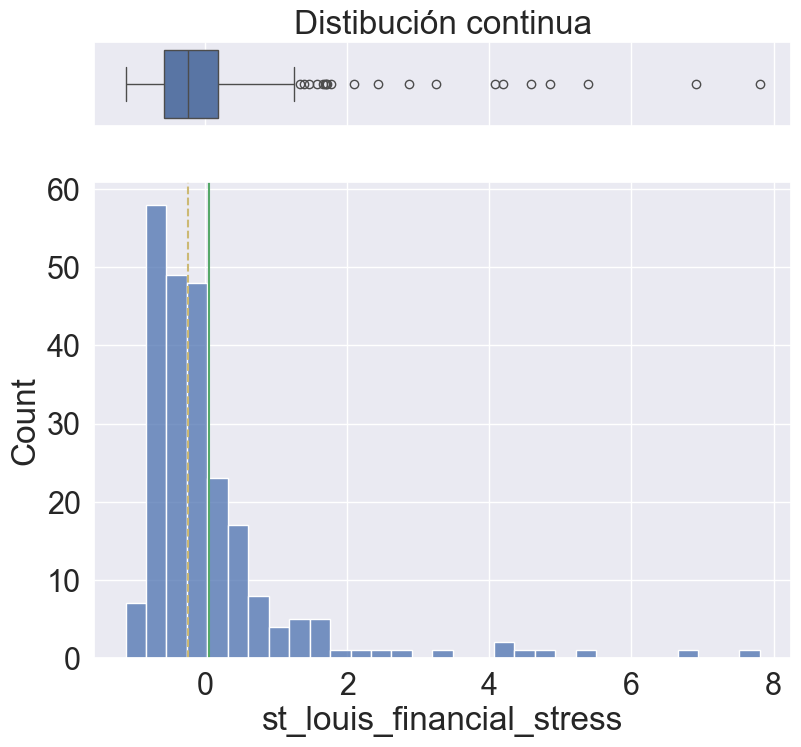

In [16]:
# Graficar columna
col = 'st_louis_financial_stress'
plot_col(df_features[col])

Notas:
* Outliers: ya que se buscan detectar los shocks económicos y las crisis sistémicas, se mantienen los valores atípicos para no destruir los regímenes de estrés. No se tratan de fallas de medición ni ruido espurio.
* Asimetrías: se aplican a continuación transfomaciones para comprimir las colas sobre las variables de alta asimetría, empleando Yeo-Johnson para lidiar con los valores nulos y negativos.

## Transformaciones

In [17]:
# Yeo-Johnson 
yeo_cols = [
    'unemployment_rate_lag1_change_3m',
    'st_louis_financial_stress',
    'st_louis_financial_stress_change_1m',
    'vix_index'
    ]
df_transformed = yeo_transform(df_features, cols=yeo_cols)
show_asymmetry(df_transformed)

m2_money_supply_lag1_ret_12m               1.548743
oil_ret_12m                                1.480572
oil_ret_1m                                 1.464026
vix_index_ret_1m                           1.431929
unemployment_rate_lag1_change_12m          1.310931
cpi_headline_lag1_ret_12m                  1.109424
spy                                        1.026533
real_yield_10y_change_1m                   0.674835
dxy_broad_goods_ret_1m                     0.559001
gold_ret_12m                               0.537232
fed_funds_rate_lag1_change_12m             0.342697
st_louis_financial_stress_yeo              0.100273
vix_index_yeo                              0.047895
real_yield_10y                            -0.023345
gold_ret_1m                               -0.191766
st_louis_financial_stress_change_1m_yeo   -0.326330
spy_ret_1m                                -0.535778
spy_ret_12m                               -0.872715
unemployment_rate_lag1_change_3m_yeo      -0.915027
industrial_p

Cont


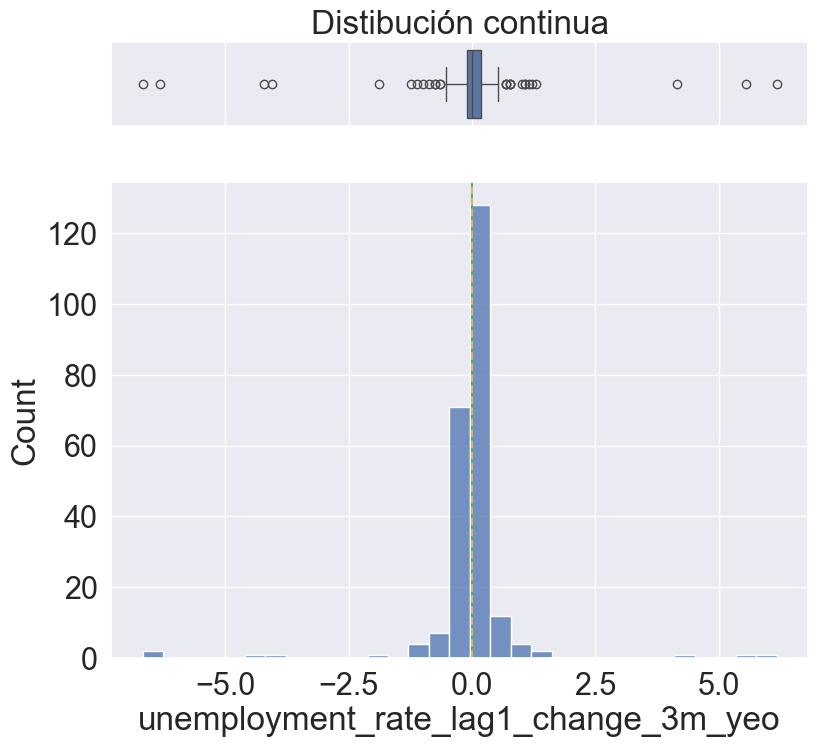

In [18]:
# Visualizar post transformación
col = 'unemployment_rate_lag1_change_3m_yeo'
plot_col(df_transformed[col])

In [19]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 236 entries, 2007-02-28 to 2026-09-30
Data columns (total 20 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   real_yield_10y                           236 non-null    float64
 1   spy                                      236 non-null    float64
 2   oil_ret_1m                               236 non-null    float64
 3   gold_ret_1m                              236 non-null    float64
 4   spy_ret_1m                               236 non-null    float64
 5   dxy_broad_goods_ret_1m                   236 non-null    float64
 6   vix_index_ret_1m                         236 non-null    float64
 7   oil_ret_12m                              236 non-null    float64
 8   gold_ret_12m                             236 non-null    float64
 9   spy_ret_12m                              236 non-null    float64
 10  cpi_headline_lag1_ret_12m      

## Guardar fichero de datos limpios

In [20]:
# Asegurar que los directorios existan
clean_data_file.parent.mkdir(parents=True, exist_ok=True)

# Guardar el dataframe
df_transformed.to_parquet(clean_data_file)
print("Fichero guardado.\nContinuar con el notebook 02_Modeling para la fase siguiente.")


Fichero guardado.
Continuar con el notebook 02_Modeling para la fase siguiente.
